# ASVspoof 2019 — LCNN Separate LA & PA Training
Two independent models trained and evaluated per the official ASVspoof 2019 scoring protocol.
- **Model LA**: trained on LA (logical access / synthetic speech)
- **Model PA**: trained on PA (physical access / replay attacks)
- Metrics reported separately: EER and min t-DCF on dev and eval sets

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchaudio
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, confusion_matrix, roc_curve
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

# ── PATHS ──────────────────────────────────────────────────────────────────────
BASE_DIR_LA = '/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA'
BASE_DIR_PA = '/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/PA/PA'

# LA dirs
TRAIN_DIR_LA = f'{BASE_DIR_LA}/ASVspoof2019_LA_train/flac'
DEV_DIR_LA   = f'{BASE_DIR_LA}/ASVspoof2019_LA_dev/flac'
EVAL_DIR_LA  = f'{BASE_DIR_LA}/ASVspoof2019_LA_eval/flac'

# PA dirs
TRAIN_DIR_PA = f'{BASE_DIR_PA}/ASVspoof2019_PA_train/flac'
DEV_DIR_PA   = f'{BASE_DIR_PA}/ASVspoof2019_PA_dev/flac'
EVAL_DIR_PA  = f'{BASE_DIR_PA}/ASVspoof2019_PA_eval/flac'

# LA protocols
TRAIN_PROTO_LA = f'{BASE_DIR_LA}/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt'
DEV_PROTO_LA   = f'{BASE_DIR_LA}/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.dev.trl.txt'
EVAL_PROTO_LA  = f'{BASE_DIR_LA}/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt'

# PA protocols
TRAIN_PROTO_PA = f'{BASE_DIR_PA}/ASVspoof2019_PA_cm_protocols/ASVspoof2019.PA.cm.train.trn.txt'
DEV_PROTO_PA   = f'{BASE_DIR_PA}/ASVspoof2019_PA_cm_protocols/ASVspoof2019.PA.cm.dev.trl.txt'
EVAL_PROTO_PA  = f'{BASE_DIR_PA}/ASVspoof2019_PA_cm_protocols/ASVspoof2019.PA.cm.eval.trl.txt'

# ── HYPERPARAMETERS ────────────────────────────────────────────────────────────
SAMPLE_RATE = 16000
BATCH_SIZE  = 64
N_EPOCHS    = 20
LR          = 0.0001
MAX_LEN     = 64000   # 4 seconds at 16kHz

# ── LOAD PROTOCOLS ─────────────────────────────────────────────────────────────
def load_protocol(proto_path):
    return pd.read_csv(proto_path, sep=' ', header=None,
                       names=['speaker', 'utt_id', 'attack', 'unknown', 'label'])

train_la_df = load_protocol(TRAIN_PROTO_LA)
dev_la_df   = load_protocol(DEV_PROTO_LA)
eval_la_df  = load_protocol(EVAL_PROTO_LA)

train_pa_df = load_protocol(TRAIN_PROTO_PA)
dev_pa_df   = load_protocol(DEV_PROTO_PA)
eval_pa_df  = load_protocol(EVAL_PROTO_PA)

print('── LA ──────────────────────────────────────')
print(f'  Train : {len(train_la_df):>6} | Bonafide: {(train_la_df.label=="bonafide").sum():>5} | Spoof: {(train_la_df.label=="spoof").sum():>5}')
print(f'  Dev   : {len(dev_la_df):>6} | Bonafide: {(dev_la_df.label=="bonafide").sum():>5} | Spoof: {(dev_la_df.label=="spoof").sum():>5}')
print(f'  Eval  : {len(eval_la_df):>6} | Bonafide: {(eval_la_df.label=="bonafide").sum():>5} | Spoof: {(eval_la_df.label=="spoof").sum():>5}')
print('── PA ──────────────────────────────────────')
print(f'  Train : {len(train_pa_df):>6} | Bonafide: {(train_pa_df.label=="bonafide").sum():>5} | Spoof: {(train_pa_df.label=="spoof").sum():>5}')
print(f'  Dev   : {len(dev_pa_df):>6} | Bonafide: {(dev_pa_df.label=="bonafide").sum():>5} | Spoof: {(dev_pa_df.label=="spoof").sum():>5}')
print(f'  Eval  : {len(eval_pa_df):>6} | Bonafide: {(eval_pa_df.label=="bonafide").sum():>5} | Spoof: {(eval_pa_df.label=="spoof").sum():>5}')

Device: cuda
── LA ──────────────────────────────────────
  Train :  25380 | Bonafide:  2580 | Spoof: 22800
  Dev   :  24844 | Bonafide:  2548 | Spoof: 22296
  Eval  :  71237 | Bonafide:  7355 | Spoof: 63882
── PA ──────────────────────────────────────
  Train :  54000 | Bonafide:  5400 | Spoof: 48600
  Dev   :  29700 | Bonafide:  5400 | Spoof: 24300
  Eval  : 134730 | Bonafide: 18090 | Spoof: 116640


## Dataset

In [2]:
mel_transform = T.MelSpectrogram(sample_rate=SAMPLE_RATE, n_fft=1024, hop_length=160, n_mels=80)
amplitude_to_db = T.AmplitudeToDB()

# ── SpecAugment (Fix 1) ────────────────────────────────────────────────────────
# Applied BEFORE delta computation so all 3 channels stay consistent.
# Two frequency masks + two time masks for stronger regularization.
spec_augment = nn.Sequential(
    T.FrequencyMasking(freq_mask_param=15),   # mask up to 15 mel bins
    T.FrequencyMasking(freq_mask_param=15),   # second independent freq mask
    T.TimeMasking(time_mask_param=50),        # mask up to 50 time frames
    T.TimeMasking(time_mask_param=50),        # second independent time mask
)

def get_spectrogram(waveform, augment=False):
    mel = mel_transform(waveform)           # (1, 80, T)
    mel = amplitude_to_db(mel)

    # Apply SpecAugment on mel BEFORE computing deltas
    # This ensures freq/time masks propagate consistently through delta channels.
    if augment:
        mel = spec_augment(mel)

    delta  = torchaudio.functional.compute_deltas(mel)
    delta2 = torchaudio.functional.compute_deltas(delta)
    out    = torch.cat([mel, delta, delta2], dim=0)  # (3, 80, T)
    return out

class ASVspoofDataset(Dataset):
    def __init__(self, df, audio_dir, ext='flac', max_len=MAX_LEN, training=False):
        self.df        = df.reset_index(drop=True)
        self.audio_dir = audio_dir
        self.ext       = ext
        self.max_len   = max_len
        self.training  = training
        self.label_map = {'bonafide': 1, 'spoof': 0}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row    = self.df.iloc[idx]
        utt_id = row['utt_id']
        label  = self.label_map[row['label']]
        path   = os.path.join(self.audio_dir, f'{utt_id}.{self.ext}')

        waveform, sr = torchaudio.load(path)

        if sr != SAMPLE_RATE:
            waveform = torchaudio.functional.resample(waveform, sr, SAMPLE_RATE)

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        if waveform.shape[1] < self.max_len:
            waveform = torch.nn.functional.pad(waveform, (0, self.max_len - waveform.shape[1]))
        else:
            waveform = waveform[:, :self.max_len]

        return get_spectrogram(waveform, augment=self.training), label

def make_loader(df, audio_dir, ext='flac', shuffle=False, training=False, num_workers=4):
    ds = ASVspoofDataset(df, audio_dir, ext=ext, training=training)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=num_workers, pin_memory=True)

# ── LA loaders ────────────────────────────────────────────────────────────────
train_loader_la = make_loader(train_la_df, TRAIN_DIR_LA, shuffle=True, training=True)
dev_loader_la   = make_loader(dev_la_df,   DEV_DIR_LA)
eval_loader_la  = make_loader(eval_la_df,  EVAL_DIR_LA,  num_workers=0)

# ── PA loaders ────────────────────────────────────────────────────────────────
train_loader_pa = make_loader(train_pa_df, TRAIN_DIR_PA, shuffle=True, training=True)
dev_loader_pa   = make_loader(dev_pa_df,   DEV_DIR_PA)
eval_loader_pa  = make_loader(eval_pa_df,  EVAL_DIR_PA,  num_workers=0)

print(f'LA — train: {len(train_loader_la)} batches | dev: {len(dev_loader_la)} | eval: {len(eval_loader_la)}')
print(f'PA — train: {len(train_loader_pa)} batches | dev: {len(dev_loader_pa)} | eval: {len(eval_loader_pa)}')
print('SpecAugment (Fix 1) active ✅  — 2×FreqMask(15) + 2×TimeMask(50) applied before deltas')

LA — train: 397 batches | dev: 389 | eval: 1114
PA — train: 844 batches | dev: 465 | eval: 2106
SpecAugment (Fix 1) active ✅  — 2×FreqMask(15) + 2×TimeMask(50) applied before deltas


## LCNN Model

In [3]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc   = nn.Sequential(
            nn.Linear(channels, channels // reduction),
            nn.ReLU(),
            nn.Linear(channels // reduction, channels),
            nn.Sigmoid()
        )
    def forward(self, x):
        b, c, _, _ = x.shape
        w = self.pool(x).view(b, c)
        w = self.fc(w).view(b, c, 1, 1)
        return x * w
class MFM(nn.Module):
    def __init__(self, out_channels):
        super().__init__()
        self.out_channels = out_channels

    def forward(self, x):
        return torch.max(x[:, :self.out_channels], x[:, self.out_channels:])


class MFM1D(nn.Module):
    def __init__(self, out_features):
        super().__init__()
        self.out_features = out_features

    def forward(self, x):
        return torch.max(x[:, :self.out_features], x[:, self.out_features:])


class LCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 128, kernel_size=5, padding=2), MFM(64),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=1), MFM(64),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), MFM(64),
            nn.MaxPool2d(2, 2), nn.BatchNorm2d(64),

            nn.Conv2d(64, 256, kernel_size=1), MFM(128),
            nn.Conv2d(128, 256, kernel_size=3, padding=1), MFM(128),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(128, 256, kernel_size=1), MFM(128),
            nn.Conv2d(128, 128, kernel_size=3, padding=1), MFM(64),
            nn.MaxPool2d(2, 2), nn.BatchNorm2d(64),

            nn.Conv2d(64, 128, kernel_size=1), MFM(64),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), MFM(64),
            nn.MaxPool2d(2, 2),
            ChannelAttention(64),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(64, 160), MFM1D(80),
            nn.Dropout(0.85),
            nn.Linear(80, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print(f'LCNN parameters: {sum(p.numel() for p in LCNN().parameters()):,}')

LCNN parameters: 678,410


## Training & Metric Helpers

In [4]:
def compute_eer(labels, scores):
    fpr, tpr, _ = roc_curve(labels, scores, pos_label=1)
    fnr = 1 - tpr
    idx = np.nanargmin(np.abs(fpr - fnr))
    return ((fpr[idx] + fnr[idx]) / 2) * 100


def compute_tDCF(labels, scores, Pspoof=0.05, Cmiss_cm=1, Cfa_cm=10,
                 Ptar=0.9905, Pnon=0.0095, Pfa_asv=0.0011, Pmiss_asv=0.0050):
    fpr, tpr, _ = roc_curve(labels, scores, pos_label=1)
    fnr  = 1 - tpr
    C1   = Cmiss_cm * Pspoof * (Pmiss_asv * Ptar + Pfa_asv * Pnon)
    C2   = Cfa_cm   * (1 - Pspoof) * Pfa_asv * (Ptar + Pnon)
    tDCF = C1 * fnr + C2 * fpr
    return np.min(tDCF) / min(C1, C2)


def evaluate_loader(model, loader, desc='Evaluating'):
    model.eval()
    all_labels, all_scores, all_preds = [], [], []
    with torch.no_grad():
        for specs, labels in tqdm(loader, desc=desc):
            specs = specs.to(DEVICE)
            outputs = model(specs)
            probs   = torch.softmax(outputs, dim=1)[:, 1]
            preds   = outputs.argmax(dim=1)
            all_scores.extend(probs.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_preds.extend(preds.cpu().numpy())
    return np.array(all_labels), np.array(all_scores), np.array(all_preds)


def train_model(condition, train_loader, dev_loader):
    print(f'\n{"="*55}')
    print(f'  Training LCNN — {condition}')
    print(f'{"="*55}')

    model     = LCNN().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    best_eer  = 999
    save_path = f'/kaggle/working/lcnn_best_{condition.lower()}.pt'
    n_bonafide = (train_loader.dataset.df.label == 'bonafide').sum()
    n_spoof    = (train_loader.dataset.df.label == 'spoof').sum()
    weight = torch.tensor([1.0, n_spoof / n_bonafide], dtype=torch.float32).to(DEVICE)
    criterion  = nn.CrossEntropyLoss(weight=weight, label_smoothing=0.1)
    scheduler  = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EPOCHS, eta_min=1e-6)

    best_eer  = 999
    history   = {'train_loss': [], 'train_acc': [], 'val_acc': [], 'val_eer': []}

    for epoch in range(N_EPOCHS):
        # Training
        model.train()
        train_loss, correct, total = 0, 0, 0
        for specs, labels in tqdm(train_loader, desc=f'[{condition}] Epoch {epoch+1}/{N_EPOCHS} Train'):
            specs, labels = specs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(specs)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            correct    += (outputs.argmax(1) == labels).sum().item()
            total      += labels.size(0)

        train_acc = correct / total
        avg_loss  = train_loss / len(train_loader)

        # Validation
        labels_v, scores_v, preds_v = evaluate_loader(model, dev_loader)
        val_acc = (preds_v == labels_v).mean()
        eer     = compute_eer(labels_v, scores_v)

        history['train_loss'].append(avg_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['val_eer'].append(eer)

        print(f'  Epoch {epoch+1:02d}/{N_EPOCHS} | loss {avg_loss:.4f} | '
              f'train_acc {train_acc:.4f} | val_acc {val_acc:.4f} | dev EER {eer:.2f}%')

        scheduler.step()

        if eer < best_eer:
            best_eer = eer
            torch.save(model.state_dict(), save_path)
            print(f'    → Best saved (EER={best_eer:.2f}%) ✅')

    # Load best weights back
    model.load_state_dict(torch.load(save_path))
    print(f'\n[{condition}] Training complete | Best dev EER: {best_eer:.2f}%')
    return model, history

print('Helpers ready ✅')

Helpers ready ✅


## Train Model LA

In [5]:
model_la, history_la = train_model('LA', train_loader_la, dev_loader_la)


  Training LCNN — LA


Evaluating: 100%|██████████| 389/389 [02:17<00:00,  2.83it/s]


  Epoch 01/20 | loss 0.7463 | train_acc 0.5076 | val_acc 0.7681 | dev EER 11.22%
    → Best saved (EER=11.22%) ✅


Evaluating: 100%|██████████| 389/389 [01:51<00:00,  3.47it/s]


  Epoch 02/20 | loss 0.6500 | train_acc 0.7710 | val_acc 0.8780 | dev EER 8.95%
    → Best saved (EER=8.95%) ✅


Evaluating: 100%|██████████| 389/389 [01:42<00:00,  3.81it/s]


... (31 outputs left out)

Evaluating: 100%|██████████| 389/389 [01:54<00:00,  3.38it/s]


  Epoch 19/20 | loss 0.4740 | train_acc 0.9974 | val_acc 0.9997 | dev EER 0.04%
    → Best saved (EER=0.04%) ✅


Evaluating: 100%|██████████| 389/389 [02:06<00:00,  3.08it/s]

  Epoch 20/20 | loss 0.4744 | train_acc 0.9971 | val_acc 0.9998 | dev EER 0.04%

[LA] Training complete | Best dev EER: 0.04%


## Train Model PA

In [6]:
model_pa, history_pa = train_model('PA', train_loader_pa, dev_loader_pa)


  Training LCNN — PA


Evaluating: 100%|██████████| 465/465 [03:05<00:00,  2.51it/s]


  Epoch 01/20 | loss 0.7081 | train_acc 0.5954 | val_acc 0.7662 | dev EER 10.75%
    → Best saved (EER=10.75%) ✅


Evaluating: 100%|██████████| 465/465 [02:10<00:00,  3.56it/s]


  Epoch 02/20 | loss 0.6399 | train_acc 0.7989 | val_acc 0.8839 | dev EER 9.34%
    → Best saved (EER=9.34%) ✅


Evaluating: 100%|██████████| 465/465 [02:18<00:00,  3.36it/s]


... (31 outputs left out)

Evaluating: 100%|██████████| 465/465 [02:20<00:00,  3.32it/s]


  Epoch 19/20 | loss 0.5180 | train_acc 0.9569 | val_acc 0.9766 | dev EER 2.46%


Evaluating: 100%|██████████| 465/465 [02:15<00:00,  3.43it/s]

  Epoch 20/20 | loss 0.5168 | train_acc 0.9590 | val_acc 0.9758 | dev EER 2.45%

[PA] Training complete | Best dev EER: 2.39%


## Evaluation — Dev & Eval Sets

In [7]:
results = {}

for condition, model, dev_loader, eval_loader in [
    ('LA', model_la, dev_loader_la, eval_loader_la),
    ('PA', model_pa, dev_loader_pa, eval_loader_pa),
]:
    # Dev
    labels_d, scores_d, preds_d = evaluate_loader(model, dev_loader,  desc=f'[{condition}] Dev  ')
    dev_eer  = compute_eer(labels_d, scores_d)
    dev_tDCF = compute_tDCF(labels_d, scores_d)

    # Eval
    labels_e, scores_e, preds_e = evaluate_loader(model, eval_loader, desc=f'[{condition}] Eval ')
    eval_eer  = compute_eer(labels_e, scores_e)
    eval_tDCF = compute_tDCF(labels_e, scores_e)

    results[condition] = {
        'dev_eer': dev_eer, 'dev_tDCF': dev_tDCF,
        'eval_eer': eval_eer, 'eval_tDCF': eval_tDCF,
        'dev_labels': labels_d, 'dev_preds': preds_d,
        'eval_labels': labels_e, 'eval_preds': preds_e,
    }

    print(f'\n── {condition} ──────────────────────────────────')
    print(f'  Dev  EER: {dev_eer:6.2f}%  |  Dev  t-DCF: {dev_tDCF:.4f}')
    print(f'  Eval EER: {eval_eer:6.2f}%  |  Eval t-DCF: {eval_tDCF:.4f}')

print('\n── Summary Table ────────────────────────────────────────')
print(f'{"Condition":<12} {"Dev EER":>8} {"Dev t-DCF":>10} {"Eval EER":>9} {"Eval t-DCF":>11}')
print('-' * 55)
for cond, r in results.items():
    print(f'{cond:<12} {r["dev_eer"]:>7.2f}% {r["dev_tDCF"]:>10.4f} {r["eval_eer"]:>8.2f}% {r["eval_tDCF"]:>11.4f}')

[LA] Eval : 100%|██████████| 1114/1114 [21:36<00:00,  1.16s/it]



── LA ──────────────────────────────────
  Dev  EER:   0.04%  |  Dev  t-DCF: 0.0053
  Eval EER:   2.31%  |  Eval t-DCF: 0.3949


[PA] Eval : 100%|██████████| 2106/2106 [43:34<00:00,  1.24s/it]



── PA ──────────────────────────────────
  Dev  EER:   2.39%  |  Dev  t-DCF: 0.3472
  Eval EER:   2.99%  |  Eval t-DCF: 0.3941

── Summary Table ────────────────────────────────────────
Condition     Dev EER  Dev t-DCF  Eval EER  Eval t-DCF
-------------------------------------------------------
LA              0.04%     0.0053     2.31%      0.3949
PA              2.39%     0.3472     2.99%      0.3941


## Classification Reports

In [8]:
for condition in ['LA', 'PA']:
    r = results[condition]
    print(f'\n── {condition} Dev Set ──────────────────────────────')
    print(classification_report(r['dev_labels'], r['dev_preds'],
                                target_names=['Spoof', 'Bonafide']))
    print(f'── {condition} Eval Set ─────────────────────────────')
    print(classification_report(r['eval_labels'], r['eval_preds'],
                                target_names=['Spoof', 'Bonafide']))


── LA Dev Set ──────────────────────────────
              precision    recall  f1-score   support

       Spoof       1.00      1.00      1.00     22296
    Bonafide       1.00      1.00      1.00      2548

    accuracy                           1.00     24844
   macro avg       1.00      1.00      1.00     24844
weighted avg       1.00      1.00      1.00     24844

── LA Eval Set ─────────────────────────────
              precision    recall  f1-score   support

       Spoof       1.00      0.82      0.90     63882
    Bonafide       0.39      1.00      0.56      7355

    accuracy                           0.84     71237
   macro avg       0.70      0.91      0.73     71237
weighted avg       0.94      0.84      0.87     71237


── PA Dev Set ──────────────────────────────
              precision    recall  f1-score   support

       Spoof       1.00      0.97      0.98     24300
    Bonafide       0.88      0.99      0.93      5400

    accuracy                           0.97  

## Training Curves

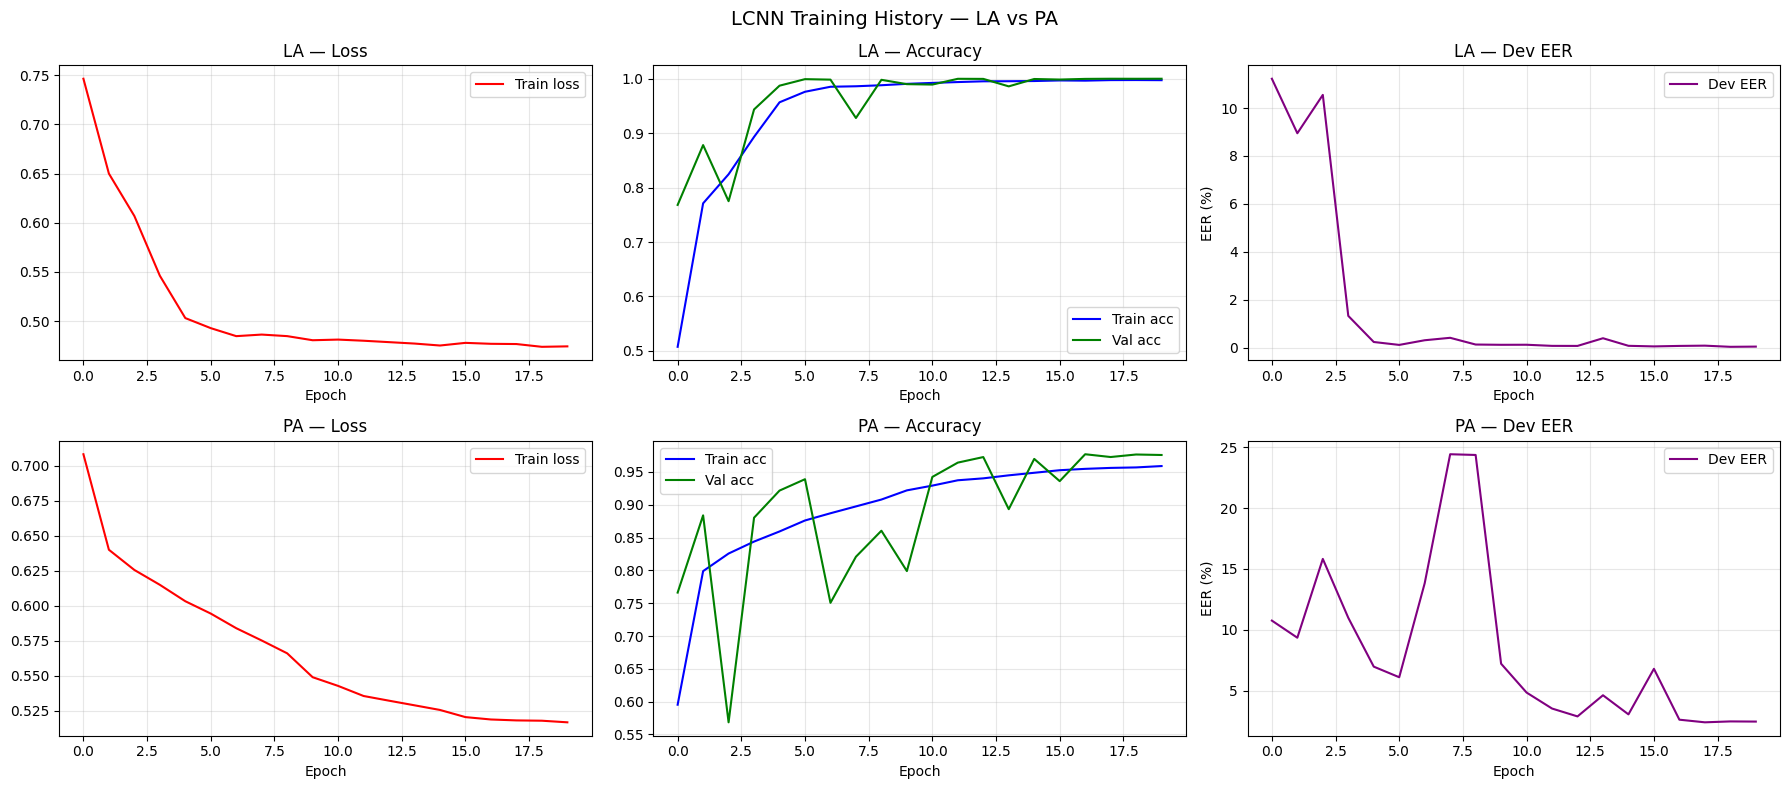

Plot saved ✅


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
fig.suptitle('LCNN Training History — LA vs PA', fontsize=14)

for i, (condition, history) in enumerate([('LA', history_la), ('PA', history_pa)]):
    ax_loss = axes[i][0]
    ax_acc  = axes[i][1]

    ax_loss.plot(history['train_loss'], color='red', label='Train loss')
    ax_loss.set_title(f'{condition} — Loss')
    ax_loss.set_xlabel('Epoch')
    ax_loss.legend()
    ax_loss.grid(alpha=0.3)

    ax_acc.plot(history['train_acc'], color='blue',  label='Train acc')
    ax_acc.plot(history['val_acc'],   color='green', label='Val acc')
    ax_acc.set_title(f'{condition} — Accuracy')
    ax_acc.set_xlabel('Epoch')
    ax_acc.legend()
    ax_acc.grid(alpha=0.3)
    ax_eer = axes[i][2]
    ax_eer.plot(history['val_eer'], color='purple', label='Dev EER')
    ax_eer.set_title(f'{condition} — Dev EER')
    ax_eer.set_xlabel('Epoch')
    ax_eer.set_ylabel('EER (%)')
    ax_eer.legend()
    ax_eer.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/lcnn_training_curves.png', dpi=150)
plt.show()
print('Plot saved ✅')

## DET Curves (Dev & Eval)

Evaluating: 100%|██████████| 2106/2106 [21:40<00:00,  1.62it/s]


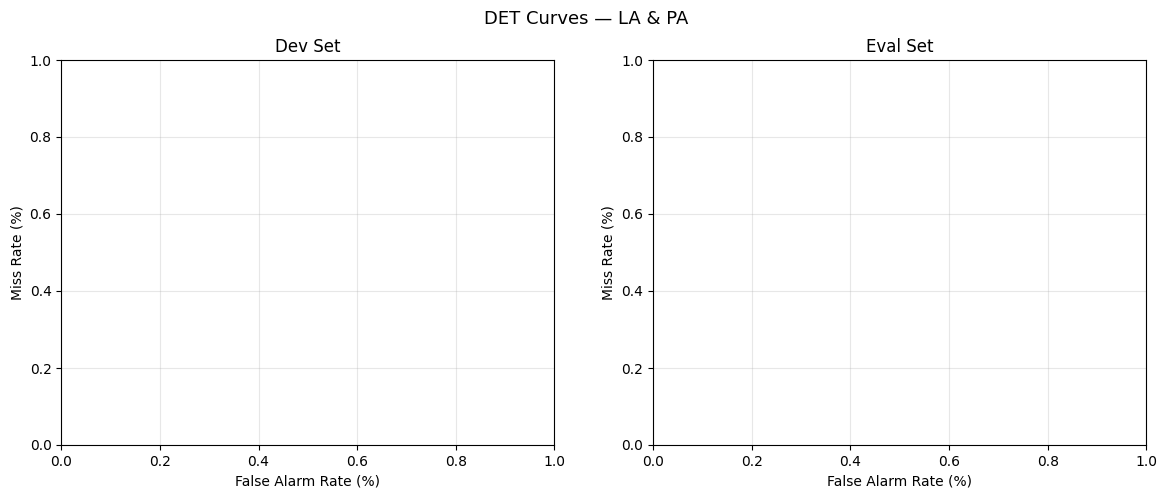

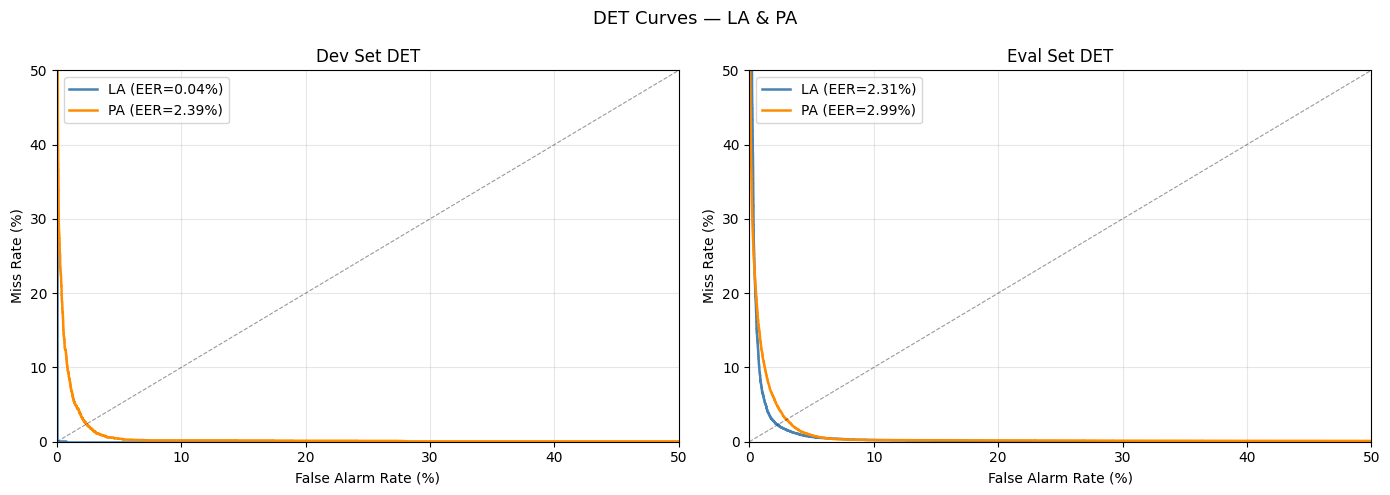

DET curves saved ✅


In [10]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('DET Curves — LA & PA', fontsize=13)

for ax, split in zip(axes, ['dev', 'eval']):
    for condition, color in [('LA', 'steelblue'), ('PA', 'darkorange')]:
        r      = results[condition]
        labels = r[f'{split}_labels']
        # re-run to get scores (stored separately below)
        ax.set_title(f'{split.capitalize()} Set')
        ax.set_xlabel('False Alarm Rate (%)')
        ax.set_ylabel('Miss Rate (%)')
        ax.grid(alpha=0.3)

# Re-collect scores for plotting
score_store = {}
for condition, model, dev_loader, eval_loader in [
    ('LA', model_la, dev_loader_la, eval_loader_la),
    ('PA', model_pa, dev_loader_pa, eval_loader_pa),
]:
    labels_d, scores_d, _ = evaluate_loader(model, dev_loader)
    labels_e, scores_e, _ = evaluate_loader(model, eval_loader)
    score_store[condition] = {
        'dev':  (labels_d, scores_d),
        'eval': (labels_e, scores_e),
    }

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('DET Curves — LA & PA', fontsize=13)

for ax, split in zip(axes, ['dev', 'eval']):
    for condition, color in [('LA', 'steelblue'), ('PA', 'darkorange')]:
        labels, scores = score_store[condition][split]
        fpr, tpr, _   = roc_curve(labels, scores, pos_label=1)
        fnr           = 1 - tpr
        eer           = results[condition][f'{split}_eer']
        ax.plot(fpr * 100, fnr * 100, color=color,
                label=f'{condition} (EER={eer:.2f}%)', linewidth=1.8)

    ax.plot([0, 100], [0, 100], 'k--', linewidth=0.8, alpha=0.4)
    ax.set_xlim(0, 50); ax.set_ylim(0, 50)
    ax.set_title(f'{split.capitalize()} Set DET')
    ax.set_xlabel('False Alarm Rate (%)')
    ax.set_ylabel('Miss Rate (%)')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/lcnn_det_curves.png', dpi=150)
plt.show()
print('DET curves saved ✅')

## Save Final Models

In [11]:
for condition, model, history in [('LA', model_la, history_la), ('PA', model_pa, history_pa)]:
    r = results[condition]
    torch.save({
        'model_state': model.state_dict(),
        'dev_eer':     r['dev_eer'],
        'dev_tDCF':    r['dev_tDCF'],
        'eval_eer':    r['eval_eer'],
        'eval_tDCF':   r['eval_tDCF'],
        'history':     history,
    }, f'/kaggle/working/lcnn_final_{condition.lower()}.pt')
    print(f'Model {condition} saved → lcnn_final_{condition.lower()}.pt ✅')

print('\n── Final Results ─────────────────────────────────────────')
print(f'{"Condition":<12} {"Dev EER":>8} {"Dev t-DCF":>10} {"Eval EER":>9} {"Eval t-DCF":>11}')
print('-' * 55)
for cond, r in results.items():
    print(f'{cond:<12} {r["dev_eer"]:>7.2f}% {r["dev_tDCF"]:>10.4f} {r["eval_eer"]:>8.2f}% {r["eval_tDCF"]:>11.4f}')

Model LA saved → lcnn_final_la.pt ✅
Model PA saved → lcnn_final_pa.pt ✅

── Final Results ─────────────────────────────────────────
Condition     Dev EER  Dev t-DCF  Eval EER  Eval t-DCF
-------------------------------------------------------
LA              0.04%     0.0053     2.31%      0.3949
PA              2.39%     0.3472     2.99%      0.3941
